Author: Malik Wensman

Email: mdwensma@ncsu.edu

Class: CSC 251-001 Fall 2026

Program: HW7

Purpose: to explore a data set using EDA

Bugs: None

Acknowledgements: None

Date: 10/9/2026

### Installation

This notebook uses pandas, NumPy, matplotlib, and seaborn to explore the ChickWeight dataset.

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

### Load CSV data file

The dataset contains chick weights over time, grouped by diet. I will read the CSV and clean the index column before analysis.

In [44]:
# Read the ChickWeight dataset
# The weight column gives the chick's body weight in grams.
# The Time column gives the number of days since birth when the weight measurement was taken.
# The Chick column identifies the individual chick.
# The Diet column indicates which of the four diets the chick received.

df = pd.read_csv("ChickWeight.csv")

print(df.head())

   Unnamed: 0  weight  Time  Chick  Diet
0           1      42     0      1     1
1           2      51     2      1     1
2           3      59     4      1     1
3           4      64     6      1     1
4           5      76     8      1     1


Removing the extra unamed column I see

In [45]:
# Remove the extra index column
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

In [46]:
# Diet is a label, a categorical variable. Not a measurement.
# later we can groupby("Diet") to get the average weight for each diet...
df["Diet"] = df["Diet"].astype("category")

print(df.head())
print("\nShape:", df.shape)

   weight  Time  Chick Diet
0      42     0      1    1
1      51     2      1    1
2      59     4      1    1
3      64     6      1    1
4      76     8      1    1

Shape: (578, 4)


### Viewing the DataFrame characteristics:

This section checks the structure, missing values, and basic descriptive statistics of the dataset.

In [47]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 578 entries, 0 to 577
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   weight  578 non-null    int64   
 1   Time    578 non-null    int64   
 2   Chick   578 non-null    int64   
 3   Diet    578 non-null    category
dtypes: category(1), int64(3)
memory usage: 14.3 KB
None


In [48]:
print("\nDescriptive statistics for weight:")
print(df["weight"].describe())



Descriptive statistics for weight:
count    578.000000
mean     121.818339
std       71.071960
min       35.000000
25%       63.000000
50%      103.000000
75%      163.750000
max      373.000000
Name: weight, dtype: float64


In [49]:
print("\nNumber of chicks:", df["Chick"].nunique())


Number of chicks: 50


#### General measurements and distribution checks

In [50]:
# General measurements and distribution checks
rows_per_chick = df.groupby("Chick").size()
print("Rows per chick summary:")
print(rows_per_chick.describe())

Rows per chick summary:
count    50.000000
mean     11.560000
std       1.667945
min       2.000000
25%      12.000000
50%      12.000000
75%      12.000000
max      12.000000
dtype: float64


In [51]:
print("\nObservations by diet:")
print(df.groupby("Diet").size())


Observations by diet:
Diet
1    220
2    120
3    120
4    118
dtype: int64


In [52]:
print("\nChicks per diet:")
print(df.groupby("Diet")["Chick"].nunique())


Chicks per diet:
Diet
1    20
2    10
3    10
4    10
Name: Chick, dtype: int64


##### Mean weight by time to summarize growth trend

In [53]:
# mean weight by time to summarize growth trend
print("\nMean weight by Time:")
print(df.groupby("Time")["weight"].mean().round(2))


Mean weight by Time:
Time
0      41.06
2      49.22
4      59.96
6      74.31
8      91.24
10    107.84
12    129.24
14    143.81
16    168.09
18    190.19
20    209.72
21    218.69
Name: weight, dtype: float64


#### Overall description of the data (so far):

- There are 50 chicks in the dataset, and each chick is measured several times across the study.
- The dataset contains 578 total observations, which means most chicks have about 11 to 12 measurements.
- Diet 1 has the most chicks (20), while Diets 2, 3, and 4 each have 10 chicks.
- Weight increases greatly over time from around 41 grams at day 0 to more than 200 grams by day 21.

### Deeper Analysis:

#### Initial questions generated before deeper analysis:

1. Do chicks on different diets grow at different rates?
2. Which diet produces the highest final chick weight?
3. How much does chick weight vary across time and among individual chicks?

#### One additional column added to the DataFrame to provide insight into the data:

I created a new variable called weight_gain that measures how much each chick gained relative to its starting weight.

In [54]:
# Add a new column to measure growth from each chick's starting weight.
# This makes mathematical sense because each chick's growth can be compared to its own baseline.

df["weight_gain"] = df.groupby("Chick")["weight"].transform(lambda x: x - x.iloc[0])

# Get the firt 12 because for Chick 1, there are 12 rows.
print(df[["Chick", "Diet", "Time", "weight", "weight_gain"]].head(12).to_string(index=False))

 Chick Diet  Time  weight  weight_gain
     1    1     0      42            0
     1    1     2      51            9
     1    1     4      59           17
     1    1     6      64           22
     1    1     8      76           34
     1    1    10      93           51
     1    1    12     106           64
     1    1    14     125           83
     1    1    16     149          107
     1    1    18     171          129
     1    1    20     199          157
     1    1    21     205          163


#### Grouping by similar characteristics:

The next step groups the data by diet and time to compare growth patterns across treatment groups.

In [55]:
# Group by diet and time to compare average growth trends (question 1)
mean_weight_by_diet_time = df.groupby(["Diet", "Time"], as_index=False)["weight"].mean()
print(mean_weight_by_diet_time.head(20).to_string(index=False))

Diet  Time     weight
   1     0  41.400000
   1     2  47.250000
   1     4  56.473684
   1     6  66.789474
   1     8  79.684211
   1    10  93.052632
   1    12 108.526316
   1    14 123.388889
   1    16 144.647059
   1    18 158.941176
   1    20 170.411765
   1    21 177.750000
   2     0  40.700000
   2     2  49.400000
   2     4  59.800000
   2     6  75.400000
   2     8  91.700000
   2    10 108.500000
   2    12 131.300000
   2    14 141.900000


In [56]:
# Final weight by chick and diet for clearer treatment comparison
final_weight_by_chick = df.groupby(["Diet", "Chick"], as_index=False)["weight"].last().rename(columns={"weight": "final_weight"})

print(final_weight_by_chick)

   Diet  Chick  final_weight
0     1      1           205
1     1      2           215
2     1      3           202
3     1      4           157
4     1      5           223
5     1      6           157
6     1      7           305
7     1      8           125
8     1      9            98
9     1     10           124
10    1     11           175
11    1     12           205
12    1     13            96
13    1     14           266
14    1     15            68
15    1     16            54
16    1     17           142
17    1     18            35
18    1     19           157
19    1     20           117
20    2     21           331
21    2     22           167
22    2     23           175
23    2     24            74
24    2     25           265
25    2     26           251
26    2     27           192
27    2     28           233
28    2     29           309
29    2     30           150
30    3     31           256
31    3     32           305
32    3     33           147
33    3     34

In [57]:
print("\nAverage final weight by diet:")
# (question 2)
print(final_weight_by_chick.groupby("Diet")["final_weight"].mean().round(2))


Average final weight by diet:
Diet
1    156.3
2    214.7
3    270.3
4    229.3
Name: final_weight, dtype: float64


#### Overall description of the data (so far):

- There are 50 chicks in the dataset, and each chick is measured several times across the study.
- The dataset contains 578 total observations, which means most chicks have about 11 to 12 measurements.
- Diet 1 has the most chicks (20), while Diets 2, 3, and 4 each have 10 chicks.
- Weight increases greatly over time from around 41 grams at day 0 to more than 200 grams by day 21.

(New Findings):
- The largest weights are near the end of the study, and the highest observed values appear around 300 to 373 grams.
- Diet 3 proved to give the biggest final weight on average

#### Four plots to visualize the dataset:

I include a histogram, a boxplot, and a growth-line plot so the analysis uses a mix of univariate and bivariate graphics.

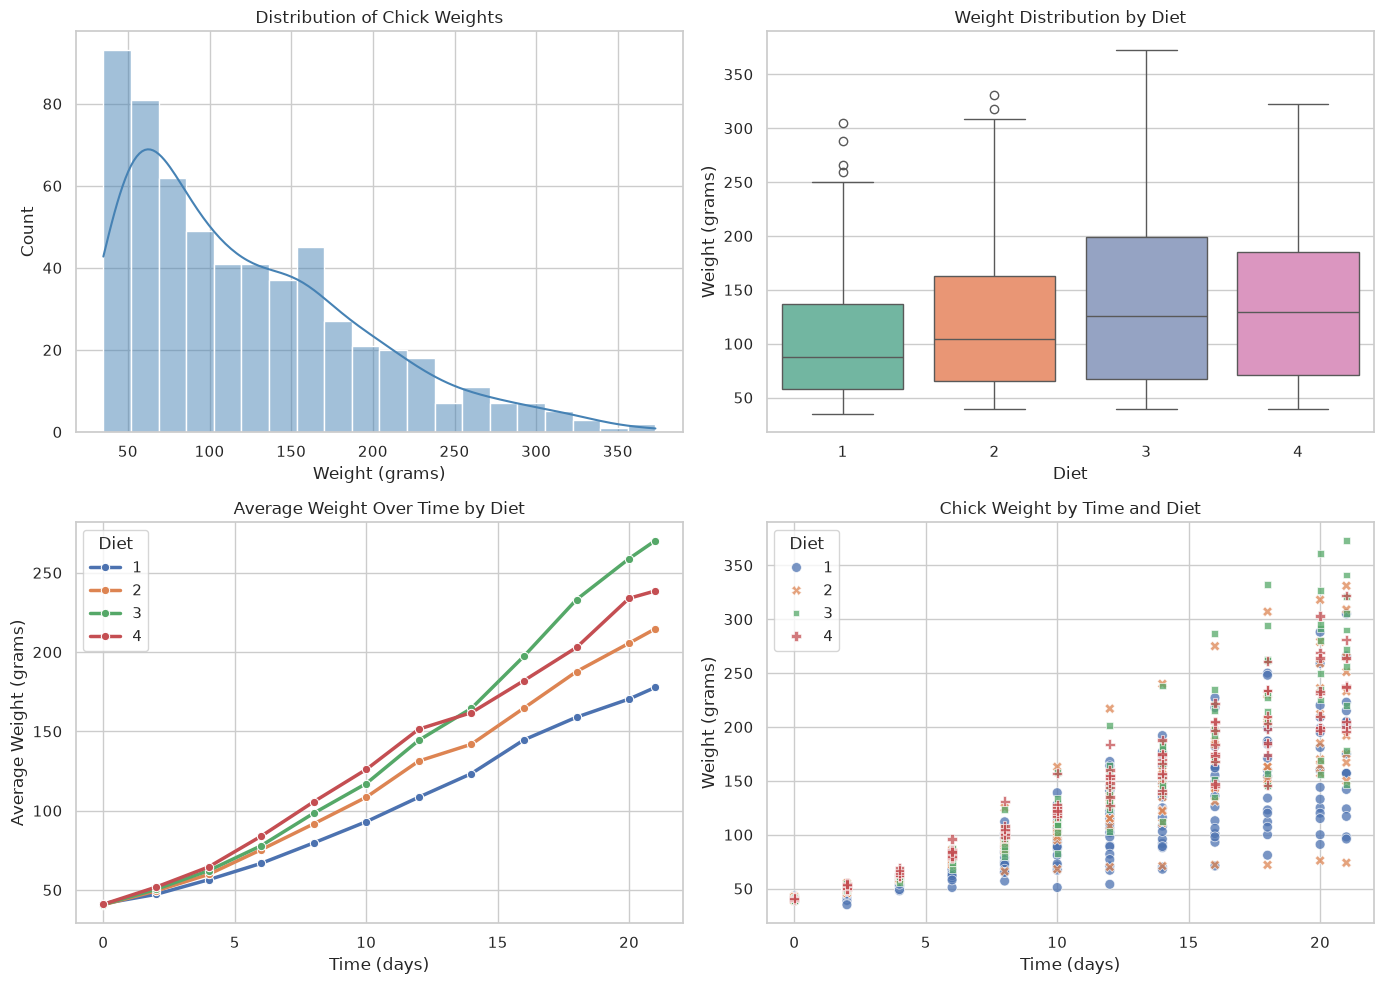

In [58]:
# 4 plots to visualize the data set

# This figure contains four plots and includes multiple graph types.
# The histogram is univariate; the boxplot and line plots compare weight across diets and time (bivariate).

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# I can use fig later to .savefig("chickweight_analysis.png"), clear()...

# Plot 1: Distribution of weights
# split the data in 20 equal width bins, gives a more detailed view
# includes a curve, Kernal Density Estimate (KDE) to show the distribution shape
# put in the first subplot (top left axes[0, 0])
sns.histplot(data=df, x="weight", bins=20, kde=True, color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Chick Weights")
axes[0, 0].set_xlabel("Weight (grams)")
axes[0, 0].set_ylabel("Count")

# Plot 2: Boxplot of weights by diet
# colors each diet a different hue. Uses set2 because of the nice color palette.
# dodge=False so boxes are only little space between them
sns.boxplot(data=df, x="Diet", y="weight", hue="Diet", palette="Set2", dodge=False, ax=axes[0, 1], legend=False)
axes[0, 1].set_title("Weight Distribution by Diet")
axes[0, 1].set_xlabel("Diet")
axes[0, 1].set_ylabel("Weight (grams)")
# (this helps visualize question 2)

# Plot 3: Lineplot to show Growth trend over time by diet
# hue makes each diet get a dif color
# marker o adds a circle marker at each data point
sns.lineplot(
    data=mean_weight_by_diet_time,
    x="Time",
    y="weight",
    hue="Diet",
    marker="o",
    linewidth=2.5,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Average Weight Over Time by Diet")
axes[1, 0].set_xlabel("Time (days)")
axes[1, 0].set_ylabel("Average Weight (grams)")
# (answers question 1, 2, and 3)

# Plot 4: Scatterplot showing individual chick growth over time (Customized)
sns.scatterplot(
    data=df,
    x="Time",
    y="weight",
    hue="Diet",
    style="Diet",
    s=50, # size of markers
    alpha=0.75, # transparency 
    ax=axes[1, 1]
)
axes[1, 1].set_title("Chick Weight by Time and Diet")
axes[1, 1].set_xlabel("Time (days)")
axes[1, 1].set_ylabel("Weight (grams)")
# Customized the marker, transparency, size...

plt.tight_layout()
plt.show()

##### About the customization of the plots:

The growth plot is more customized than the other plots because I intentionally used several advanced seaborn and Matplotlib styling options to make the diet differences easier to interpret. In the scatterplot, I used hue="Diet" to color points by diet, style="Diet" to assign different marker shapes to each diet, and s=50 to enlarge the markers so they stand out more clearly. I also applied alpha=0.75 to make the points slightly transparent, which helps when many observations overlap and makes the distribution easier to read. This was a more custom visual encoding than the simpler plots, which mostly used default settings or a single grouping variable.

In contrast, the other plots were more standard: the histogram used kde=True to add a smooth density curve, the boxplot used palette="Set2" and dodge=False to control color and spacing, and the line plot used linewidth=2.5 to make the trend lines easier to see. 

##### Overall description of the data:

- There are 50 chicks in the dataset, and each chick is measured several times across the study.
- The dataset contains 578 total observations, which means most chicks have about 11 to 12 measurements.
- Diet 1 has the most chicks (20), while Diets 2, 3, and 4 each have 10 chicks.
- Weight increases greatly over time from around 41 grams at day 0 to more than 200 grams by day 21.
- The largest weights are near the end of the study, and the highest observed values appear around 300 to 373 grams.
- Diet 3 proved to give the biggest final weight on average

(New Findings):
- The distribution of weight is right-skewed because a few chicks become much heavier than the rest in later time points.
- Didn't see any missing values in the dataset, and the growth pattern looks smooth and consistent across time.

### Description of the variation and correlations in the data:

The visualizations show a strong positive relationship between time and chick weight. As the number of days increases, every chick gains weight, and the average pattern is nearly linear in the first half of the experiment. Diet appears to matter: the average weight curves for Diets 3 and 4 rise above Diet 1 and Diet 2 by the middle of the graph, suggesting that those diets may lead to faster or larger growth. The spread of weights also increases over time, which means individual chicks begin to differ more as they get older.

### Three observations made through the exploratory data analysis:

1. Chick weight increases steadily over time for all groups, with the strongest growth occurring between day 0 and day 21.
2. Diet has a visible effect on growth: Diet 3 and Diet 4 produced the highest final average weights, while Diet 1 had the lowest average by the end of the study.
3. There is substantial variation among individual chicks, and the spread in weight becomes larger later in the study, which suggests that some chicks grow faster than others even within the same diet.